# Prepare data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import json
import numpy as np
from PIL import Image
import os
import glob

In [2]:
image_paths = glob.glob('./data/*.jpg')
json_paths = [pth.replace('jpg', 'json') for pth in image_paths]
image_paths, json_paths

(['./data/006_IT158412_1.jpg',
  './data/008_IT158764_1.jpg',
  './data/009_IT221893_1.jpg',
  './data/010_IT223741_1.jpg',
  './data/001_IT135673_1.jpg',
  './data/004_IT158286_1.jpg',
  './data/003_IT158279_1.jpg',
  './data/011_IT223788_1.jpg',
  './data/012_IT225004_1.jpg'],
 ['./data/006_IT158412_1.json',
  './data/008_IT158764_1.json',
  './data/009_IT221893_1.json',
  './data/010_IT223741_1.json',
  './data/001_IT135673_1.json',
  './data/004_IT158286_1.json',
  './data/003_IT158279_1.json',
  './data/011_IT223788_1.json',
  './data/012_IT225004_1.json'])

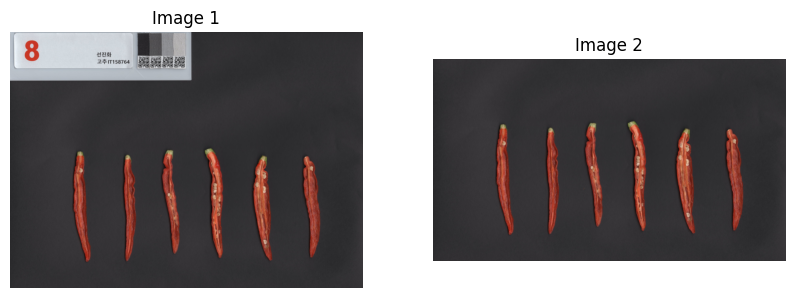

In [ ]:
image = cv2.imread(image_paths[1])
image_RGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_crop = image_RGB[540:, :, :]

plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.imshow(image_RGB)
plt.title("Image Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_crop)
plt.title("Image ")
plt.axis("off")

plt.show()

# Get Bbox

In [5]:
EP = 0.003

def hadle_segm(img, threshold=56):
    # print(type(img))
    img = img.copy()
    img = np.array(img)
    img = np.where(img >= threshold, 255, 0)

    return img
    
def get_mask(img,threshold = 16, use_closing = True, use_contour = True):
    img = img
   
    
    img_red = np.array(img[:, :, 0])
    hist = cv2.calcHist([img_red], [0], None, [256], [0, 256])

    fruit_mask = hadle_segm(img_red, hist.argmax() + threshold)
    fruit_mask = fruit_mask.astype(np.uint8)

    if use_closing:
        kernel = np.ones((10, 10), np.uint8)
        fruit_mask = cv2.morphologyEx(fruit_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
        fruit_mask = fruit_mask.astype(np.uint8)

    if use_contour:
        contours, hierarchy = cv2.findContours(fruit_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contour_areas = [cv2.contourArea(cnt) for cnt in contours]
        max_area = max(contour_areas)
        fruit_mask = np.zeros_like(fruit_mask)
        contour_line = np.zeros_like(fruit_mask)
        for cnt in contours:
            area = cv2.contourArea(cnt)
            if area >= max_area:
                cv2.drawContours(fruit_mask, [cnt], -1, (255, 255, 255), -1)

    return fruit_mask

def mask_img(img_path, ep= EP):
    img = cv2.imread(img_path)
    img_RGB = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_red = img_RGB[540:, :, 0]
    # plt.imshow(img_red)
    # plt.show()
    img_mask = get_mask(img_RGB[540:, :, :], 22 , True, False)
    # plt.imshow(img_mask)
    # plt.show()
    
    contours, hierarchy = cv2.findContours(img_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contour_areas = [cv2.contourArea(cnt) for cnt in contours]
    max_area = max(contour_areas)
    fruit_mask = img_RGB[540:, :, :]
    masks = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area >= 10000:
            # print(cnt)
            # masks.append(cnt)
            cv2.drawContours(fruit_mask, [cnt], -1, (255, 255, 255), 2)
            length_L1 = cv2.arcLength(cnt, True)
            cnt = cv2.approxPolyDP(cnt, ep*length_L1, True)
            contour = [p[0].tolist() for p in cnt]
            contour_or = [[p[0],p[1]+540] for p in contour]
            masks.append(contour_or)
    
    # plt.imshow(fruit_mask)
    # plt.show()
    return masks

### Detect bbox by threshold

In [6]:
# from segment import SegmentModel
from detect import DetectModel

model_detete = DetectModel(model_name='none')
# model_detete.predict(image_paths[0])

Use threshold for detect each chili fruit


In [ ]:
ep= 0.003
path = image_paths[1]
masks = model_detete.predict(path)
image = cv2.imread(path)
H, W, _ = image.shape

for i, mask in enumerate(masks):
    x, y, w, h = mask
    # print(x,y,w,h)
    img = image[max(0, y-50):min(H,y+h+50), max(0,x-50):min(W,x+w+50)]
    cv2.imwrite(f"tmp/output_{i}.jpg", img)
    # cv2.rectangle(image, (x-50, y-50), (x + w +50, y + h+50), (0, 255, 0), 2)

### Detect chili by model YOLO

In [ ]:
from detect import DetectModel

model_detete = DetectModel(model_name='yolo', weight_path='./pretrain/yolov7_detect_v1.pt')
# model_detete.predict(image_paths[0])

In [12]:
ep= 0.003
path = image_paths[1]
masks = model_detete.predict(path)
image = cv2.imread(path)
H, W, _ = image.shape

for i, mask in enumerate(masks):
    x, y, w, h = mask
    # print(x,y,w,h)
    img = image[max(0, y-50):min(H,y+h+50), max(0,x-50):min(W,x+w+50)]
    cv2.imwrite(f"tmp/output_{i}.jpg", img)
    # cv2.rectangle(image, (x-50, y-50), (x + w +50, y + h+50), (0, 255, 0), 2)

# Segment for each chili

# Test pipeline

# Accuracy

# App demo